In [1]:
# Run once if a library is missing:
# !pip install rasterio geopandas matplotlib pandas numpy

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask
from rasterio.plot import plotting_extent
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("Data")          # folder holding the 5 exported files
plt.rcParams["figure.dpi"] = 110

for f in sorted(DATA.glob("*")):
    print(f.name)

In [2]:
from pathlib import Path

DATA = Path(".")

files = (
    list(DATA.glob("*.tif")) +
    list(DATA.glob("*.csv")) +
    list(DATA.glob("*.geojson"))
)

for f in sorted(files):
    print(f.name)

Eastern_boundary.geojson
Eastern_NO2_Jul2025.tif
Eastern_NO2_monthly.csv
Eastern_NO2_Nov2025.tif
Province_NO2_2025.csv
SriLanka_NO2_Jul2025.tif
SriLanka_NO2_Nov2025.tif
SriLanka_provinces.geojson


In [3]:
jul_path = DATA / "SriLanka_NO2_Jul2025.tif"
nov_path = DATA / "SriLanka_NO2_Nov2025.tif"

with rasterio.open(jul_path) as src:
    print("CRS        :", src.crs)
    print("Size       :", src.width, "x", src.height, "pixels")
    print("Bands      :", src.count)
    print("Pixel size :", src.res, "(degrees)")
    print("Bounds     :", src.bounds)
    print("No-data    :", src.nodata)
    print("Data type  :", src.dtypes[0])

CRS        : EPSG:4326
Size       : 264 x 420 pixels
Bands      : 1
Pixel size : (0.010000045742818514, 0.010000045742818514) (degrees)
Bounds     : BoundingBox(left=79.38036310649336, bottom=5.780026439349102, right=82.02037518259745, top=9.980045651332878)
No-data    : None
Data type  : float32


In [4]:
NODATA = -9999
TO_UMOL = 1e6   # mol/m² -> µmol/m²

def read_no2(path):
    with rasterio.open(path) as src:
        arr = src.read(1).astype("float64")
        extent = plotting_extent(src)

    # Handle NoData values
    arr[arr == NODATA] = np.nan

    # Convert from mol/m² to µmol/m²
    return arr * TO_UMOL, extent

# Read July and November rasters
jul, extent = read_no2(DATA / "SriLanka_NO2_Jul2025.tif")
nov, _ = read_no2(DATA / "SriLanka_NO2_Nov2025.tif")

# Summary statistics
print("July  : min %.1f  max %.1f µmol/m²" % (np.nanmin(jul), np.nanmax(jul)))
print("Nov   : min %.1f  max %.1f µmol/m²" % (np.nanmin(nov), np.nanmax(nov)))
print("No-data pixels — July:", np.isnan(jul).sum(),
      " Nov:", np.isnan(nov).sum())


July  : min -17.6  max 27.4 µmol/m²
Nov   : min -10.1  max 48.5 µmol/m²
No-data pixels — July: 421  Nov: 431


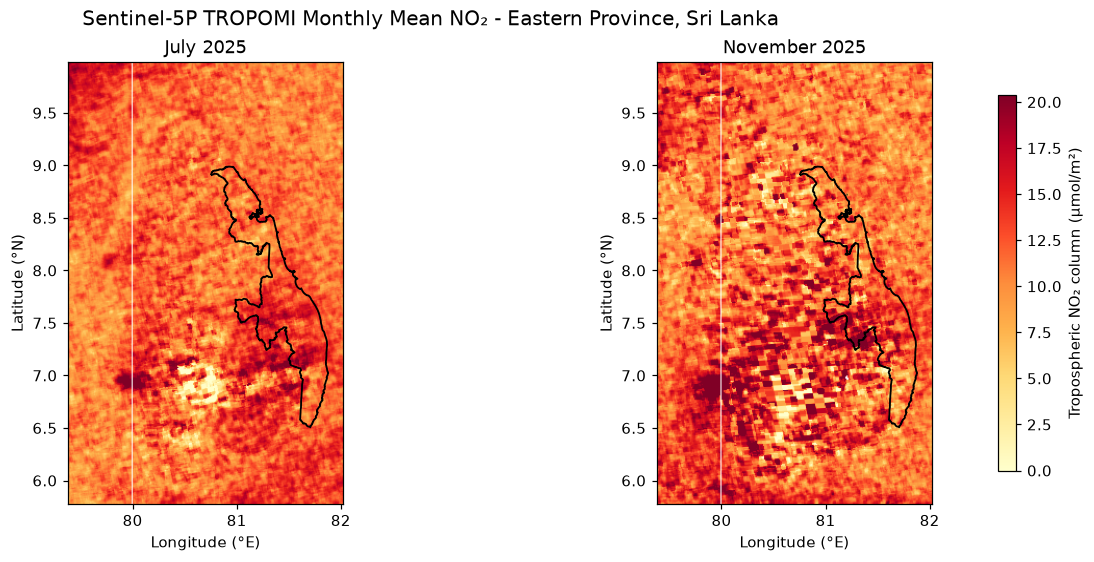

In [5]:
# Load Eastern Province boundary
eastern = gpd.read_file(DATA / "Eastern_boundary.geojson").to_crs("EPSG:4326")

# Same colour scale for both months
vmin = 0
vmax = np.nanpercentile(
    np.concatenate([jul.ravel(), nov.ravel()]), 98
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

for ax, arr, title in zip(
    axes,
    [jul, nov],
    ["July 2025", "November 2025"]
):
    im = ax.imshow(
        arr,
        extent=extent,
        cmap="YlOrRd",
        vmin=vmin,
        vmax=vmax
    )

    eastern.boundary.plot(ax=ax, color="black", linewidth=1.2)

    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)")

fig.colorbar(
    im,
    ax=axes,
    shrink=0.85,
    label="Tropospheric NO₂ column (µmol/m²)"
)

fig.suptitle(
    "Sentinel-5P TROPOMI Monthly Mean NO₂ - Eastern Province, Sri Lanka",
    fontsize=13
)

plt.show()

In [6]:
def clip_to_eastern(path):
    with rasterio.open(path) as src:
        out, _ = mask(
            src,
            eastern.geometry,
            crop=True,
            nodata=NODATA,
            filled=True
        )

    arr = out[0].astype("float64")
    arr[arr == NODATA] = np.nan

    return arr * TO_UMOL

# Clip July and November rasters
jul_d = clip_to_eastern(DATA / "Eastern_NO2_Jul2025.tif")
nov_d = clip_to_eastern(DATA / "Eastern_NO2_Nov2025.tif")

# Summary statistics
def summary(arr):
    v = arr[~np.isnan(arr)]
    return {
        "pixels": v.size,
        "mean": v.mean(),
        "median": np.median(v),
        "min": v.min(),
        "max": v.max(),
        "std": v.std()
    }

stats = pd.DataFrame({
    "July 2025": summary(jul_d),
    "Nov 2025": summary(nov_d)
}).T.round(1)


In [7]:
pct = (
    (stats.loc["Nov 2025", "mean"] - stats.loc["July 2025", "mean"])
    / stats.loc["July 2025", "mean"]
    * 100
)

ratio = (
    stats.loc["Nov 2025", "mean"]
    / stats.loc["July 2025", "mean"]
)

print(f"Mean NO₂ over Eastern Province changed by {pct:+.1f}% from July to November")
print(f"November is {ratio:.1f}× the July level")

Mean NO₂ over Eastern Province changed by -5.4% from July to November
November is 0.9× the July level


In [8]:
def summary(arr):
    v = arr[~np.isnan(arr)]
    return {
        "pixels": v.size,
        "mean": v.mean(),
        "median": np.median(v),
        "min": v.min(),
        "max": v.max(),
        "std": v.std()
    }

stats = pd.DataFrame({
    "July 2025": summary(jul_d),
    "Nov 2025": summary(nov_d)
}).T.round(1)

print(stats)

           pixels  mean  median  min   max  std
July 2025  8058.0  12.9    12.8  3.7  23.5  2.9
Nov 2025   8058.0  12.2    11.9 -3.2  35.3  4.2


In [9]:
pct = (
    (stats.loc["Nov 2025", "mean"] - stats.loc["July 2025", "mean"])
    / stats.loc["July 2025", "mean"]
    * 100
)

ratio = (
    stats.loc["Nov 2025", "mean"]
    / stats.loc["July 2025", "mean"]
)

print(f"Mean NO₂ over Eastern Province changed by {pct:+.1f}% from July to November")
print(f"November is {ratio:.1f}× the July level")

Mean NO₂ over Eastern Province changed by -5.4% from July to November
November is 0.9× the July level


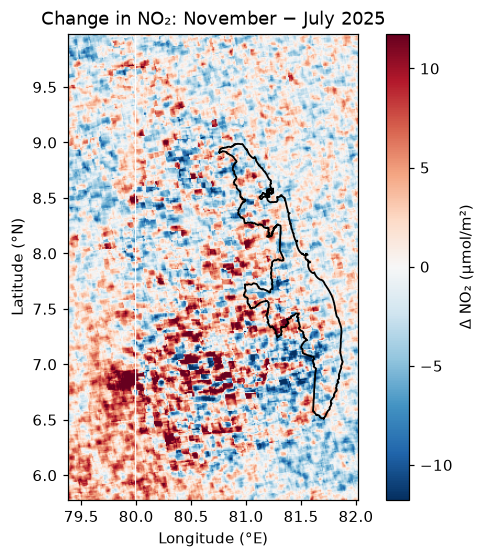

In [10]:
# Difference map (November - July)
diff = nov - jul

# Symmetric colour limits
lim = np.nanpercentile(np.abs(diff), 98)

fig, ax = plt.subplots(figsize=(6.5, 5.5))

im = ax.imshow(
    diff,
    extent=extent,
    cmap="RdBu_r",
    vmin=-lim,
    vmax=lim
)

# Plot Eastern Province boundary
eastern.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.2
)

ax.set_title("Change in NO₂: November − July 2025")
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")

fig.colorbar(
    im,
    ax=ax,
    label="Δ NO₂ (µmol/m²)"
)

plt.show()

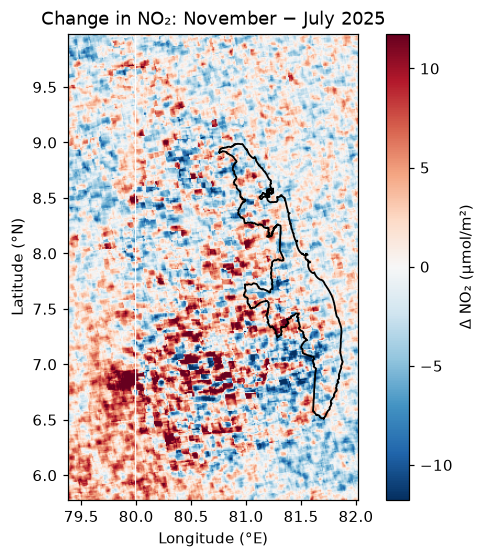

In [11]:
# Difference map (November - July)
diff = nov - jul

# Symmetric colour limits
lim = np.nanpercentile(np.abs(diff), 98)

fig, ax = plt.subplots(figsize=(6.5, 5.5))

im = ax.imshow(
    diff,
    extent=extent,
    cmap="RdBu_r",
    vmin=-lim,
    vmax=lim
)

# Plot Eastern Province boundary
eastern.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.2
)

ax.set_title("Change in NO₂: November − July 2025")
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")

fig.colorbar(
    im,
    ax=ax,
    label="Δ NO₂ (µmol/m²)"
)

plt.show()

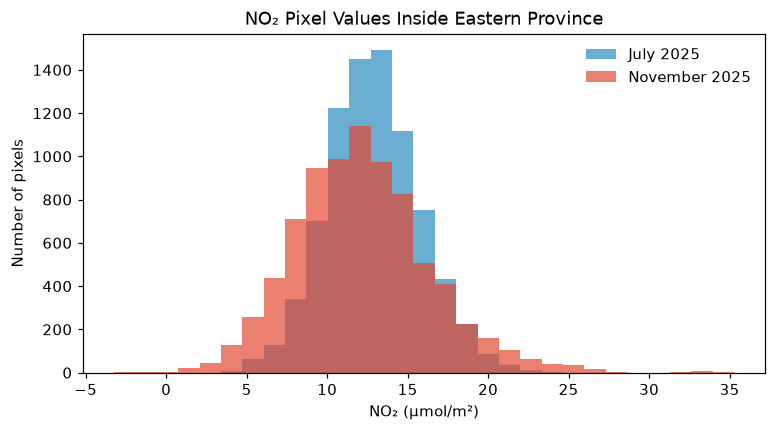

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))

bins = np.linspace(
    np.nanmin([jul_d, nov_d]),
    np.nanmax([jul_d, nov_d]),
    30
)

ax.hist(
    jul_d[~np.isnan(jul_d)],
    bins=bins,
    alpha=0.7,
    label="July 2025",
    color="#2b8cbe"
)

ax.hist(
    nov_d[~np.isnan(nov_d)],
    bins=bins,
    alpha=0.7,
    label="November 2025",
    color="#e34a33"
)

ax.set_xlabel("NO₂ (µmol/m²)")
ax.set_ylabel("Number of pixels")
ax.set_title("NO₂ Pixel Values Inside Eastern Province")

ax.legend(frameon=False)

plt.show()

In [13]:
ts = pd.read_csv(
    DATA / "Eastern_NO2_monthly.csv",
    parse_dates=["date"]
)

ts["no2"] = ts["no2_mol_m2"] * TO_UMOL

ts = ts.sort_values("date").reset_index(drop=True)

print("Months:", len(ts))
print("Missing values:", ts["no2"].isna().sum())

ts.head()

Months: 93
Missing values: 0


,date,no2_mol_m2,n_images,no2
0,2019-01-01,0.000010,440,10.177113
1,2019-02-01,0.000010,396,10.319213
2,2019-03-01,0.000014,440,14.375449
3,2019-04-01,0.000013,417,13.410239
4,2019-05-01,0.000015,440,14.577977


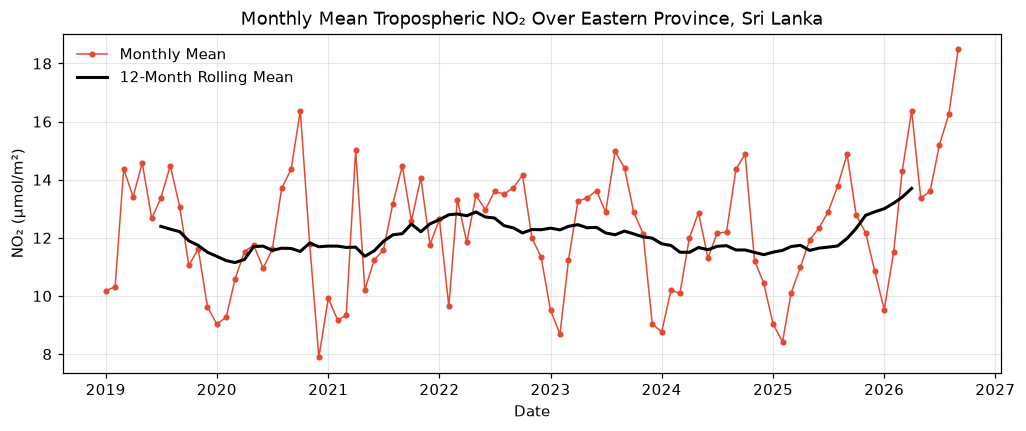

In [14]:
# 12-month rolling mean
ts["rolling_12"] = ts["no2"].rolling(
    12,
    center=True,
    min_periods=12
).mean()

# Plot time series
fig, ax = plt.subplots(figsize=(11, 4))

ax.plot(
    ts["date"],
    ts["no2"],
    marker="o",
    markersize=3,
    linewidth=1,
    color="#e34a33",
    label="Monthly Mean"
)

ax.plot(
    ts["date"],
    ts["rolling_12"],
    color="black",
    linewidth=2,
    label="12-Month Rolling Mean"
)

ax.set_ylabel("NO₂ (µmol/m²)")
ax.set_xlabel("Date")
ax.set_title("Monthly Mean Tropospheric NO₂ Over Eastern Province, Sri Lanka")

ax.legend(frameon=False)
ax.grid(alpha=0.3)

plt.show()

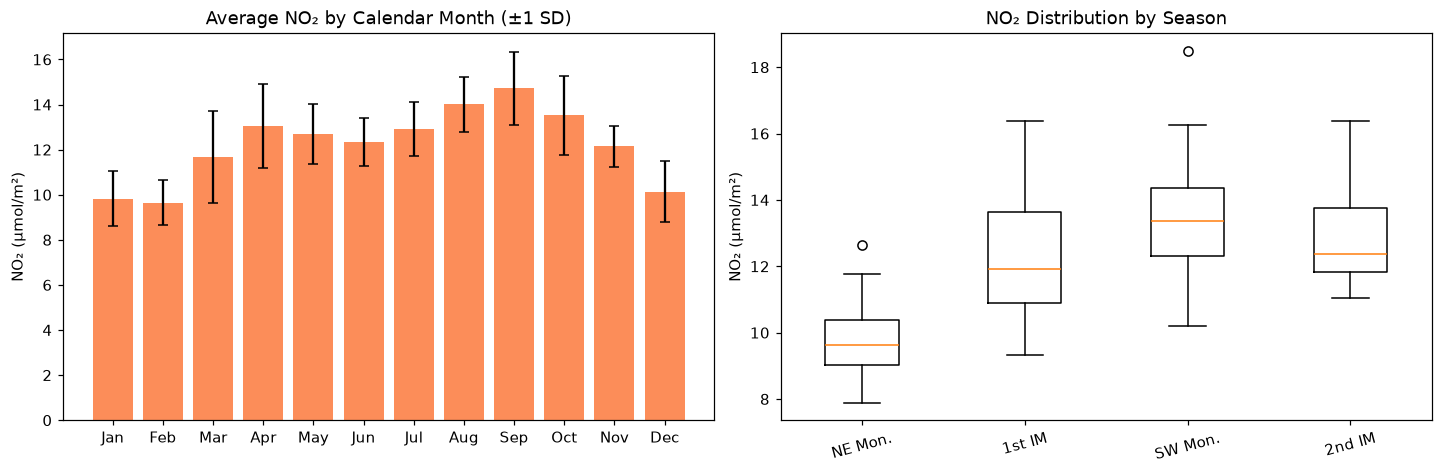

season
Northeast Monsoon        9.9
First Inter-monsoon     12.4
Southwest Monsoon       13.3
Second Inter-monsoon    12.8
Name: no2, dtype: float64


In [15]:
# Extract month
ts["month"] = ts["date"].dt.month

# Define seasons for Sri Lanka
def season(m):
    if m in (12, 1, 2):
        return "Northeast Monsoon"
    elif m in (3, 4):
        return "First Inter-monsoon"
    elif m in (5, 6, 7, 8, 9):
        return "Southwest Monsoon"
    else:
        return "Second Inter-monsoon"

ts["season"] = ts["month"].apply(season)

# Monthly climatology
clim = ts.groupby("month")["no2"].agg(["mean", "std"])

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# Plot
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4.2),
    constrained_layout=True
)

# Monthly averages
axes[0].bar(
    month_names,
    clim["mean"],
    yerr=clim["std"],
    capsize=3,
    color="#fc8d59"
)

axes[0].set_ylabel("NO₂ (µmol/m²)")
axes[0].set_title("Average NO₂ by Calendar Month (±1 SD)")

# Seasonal boxplots
order = [
    "Northeast Monsoon",
    "First Inter-monsoon",
    "Southwest Monsoon",
    "Second Inter-monsoon"
]

data = [
    ts.loc[ts["season"] == s, "no2"].dropna()
    for s in order
]

axes[1].boxplot(data)

axes[1].set_xticks(range(1, len(order) + 1))
axes[1].set_xticklabels(
    ["NE Mon.", "1st IM", "SW Mon.", "2nd IM"],
    rotation=15
)

axes[1].set_ylabel("NO₂ (µmol/m²)")
axes[1].set_title("NO₂ Distribution by Season")

plt.show()

# Seasonal means
seasonal_means = (
    ts.groupby("season")["no2"]
      .mean()
      .reindex(order)
      .round(1)
)

print(seasonal_means)

In [17]:
import pandas as pd

# Read file
provinces = pd.read_csv(DATA / "Province_NO2_2025.csv")

# Show columns and first rows
print("Columns in file:")
print(provinces.columns.tolist())

print("\nFirst 5 rows:")
display(provinces.head())

Columns in file:
['province', 'no2_mol_m2']

First 5 rows:


,province,no2_mol_m2
0,Central,0.000012
1,Eastern,0.000012
2,North Central,0.000012
3,North Western,0.000013
4,Northern,0.000011


Available columns:
['province', 'no2_mol_m2']
Province column: province
NO₂ column: no2_mol_m2


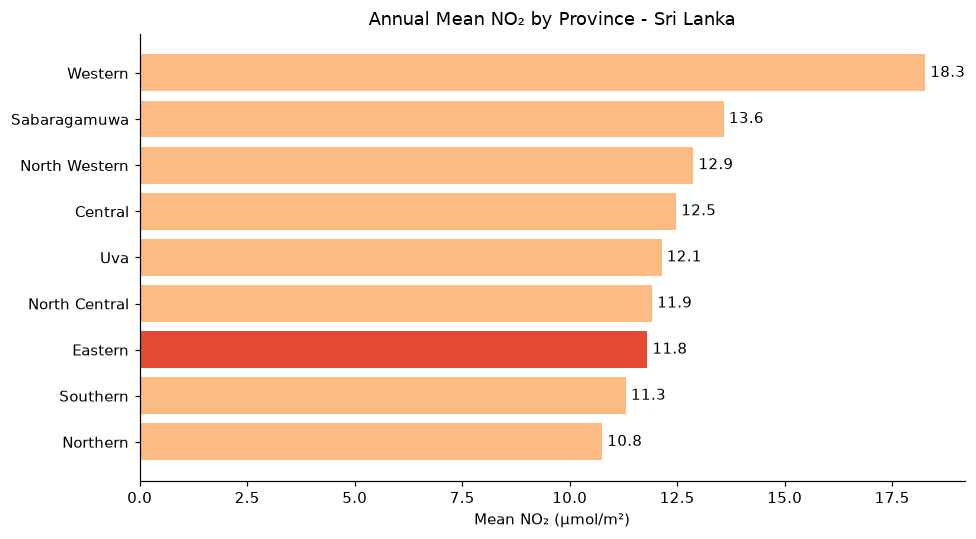

,province,no2
0,Western,18.268551
1,Sabaragamuwa,13.585534
2,North Western,12.877288
3,Central,12.477211
4,Uva,12.141551
5,North Central,11.918327
6,Eastern,11.806529
7,Southern,11.308948
8,Northern,10.758064


In [18]:
import pandas as pd
import matplotlib.pyplot as plt

# Read file
provinces = pd.read_csv(DATA / "Province_NO2_2025.csv")

print("Available columns:")
print(provinces.columns.tolist())

# Find province column
province_col = provinces.columns[0]

# Find first numeric column
numeric_cols = provinces.select_dtypes(include="number").columns

if len(numeric_cols) == 0:
    raise ValueError("No numeric NO₂ column found in CSV.")

no2_col = numeric_cols[0]

print(f"Province column: {province_col}")
print(f"NO₂ column: {no2_col}")

# Prepare data
provinces = provinces[[province_col, no2_col]].copy()
provinces.columns = ["province", "no2"]

# Convert if values are still in mol/m²
if provinces["no2"].max() < 1:
    provinces["no2"] = provinces["no2"] * 1e6

# Sort
provinces = provinces.sort_values("no2")

# Highlight Eastern Province
colors = [
    "#e34a33" if str(p).lower() == "eastern" else "#fdbb84"
    for p in provinces["province"]
]

# Plot
fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    provinces["province"],
    provinces["no2"],
    color=colors
)

for y, value in enumerate(provinces["no2"]):
    ax.text(
        value,
        y,
        f" {value:.1f}",
        va="center"
    )

ax.set_xlabel("Mean NO₂ (µmol/m²)")
ax.set_title("Annual Mean NO₂ by Province - Sri Lanka")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# Ranking table
ranking = (
    provinces
    .sort_values("no2", ascending=False)
    .reset_index(drop=True)
)

display(ranking)
